<a href="https://colab.research.google.com/github/EMuthomi-dev/Introduction-to-ML/blob/Assignments/Descriptive_statistics_(Week_4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4: Descriptive Statistics, Correlation and Input → Model → Output

**Project:** Pothole detection and severity classification from road images.
**Dataset:** Annotated Potholes Dataset (Kaggle, 665 road images with
bounding boxes), as imported in Week 3. Numerical variables are derived from
the bounding-box annotations.

In [1]:
!pip -q install kagglehub

import os, glob
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub

path = kagglehub.dataset_download("chitholian/annotated-potholes-dataset")

img_files = []
for ext in ("jpg", "jpeg", "png"):
    img_files += glob.glob(f"{path}/**/*.{ext}", recursive=True)
xml_files = glob.glob(f"{path}/**/*.xml", recursive=True)
img_by_stem = {os.path.splitext(os.path.basename(p))[0]: p for p in img_files}

def parse_voc(xml_path):
    root = ET.parse(xml_path).getroot()
    boxes = []
    for obj in root.findall("object"):
        bb = obj.find("bndbox")
        boxes.append((int(float(bb.find("xmin").text)), int(float(bb.find("ymin").text)),
                      int(float(bb.find("xmax").text)), int(float(bb.find("ymax").text))))
    return boxes

rows = []
for x in xml_files:
    stem = os.path.splitext(os.path.basename(x))[0]
    if stem not in img_by_stem:
        continue
    with Image.open(img_by_stem[stem]) as im:
        w, h = im.size
    boxes = parse_voc(x)
    areas = [(b[2] - b[0]) * (b[3] - b[1]) / (w * h) for b in boxes]
    rows.append({
        "image": os.path.basename(img_by_stem[stem]),
        "width_px": w,
        "n_potholes": len(boxes),
        "largest_box_area_frac": max(areas) if areas else 0.0,
        "total_box_area_frac": sum(areas),
    })

df = pd.DataFrame(rows)
print("Images:", len(df))
display(df.head())

100%|██████████| 45.9M/45.9M [00:03<00:00, 13.5MB/s]

Extracting files...


Images: 665


,image,width_px,n_potholes,largest_box_area_frac,total_box_area_frac
0,img-518.jpg,533,1,0.234428,0.234428
1,img-325.jpg,533,6,0.055216,0.103277
2,img-166.jpg,720,2,0.063920,0.069543
3,img-258.jpg,720,1,0.041522,0.041522
4,img-663.jpg,335,10,0.051582,0.159582


In [2]:
variables = ["width_px", "n_potholes", "largest_box_area_frac", "total_box_area_frac"]

stats_rows = []
for v in variables:
    x = df[v]
    stats_rows.append({
        "variable": v,
        "mean": x.mean(),
        "median": x.median(),
        "min": x.min(),
        "max": x.max(),
        "range": x.max() - x.min(),
        "variance": x.var(ddof=1),     # sample variance (n - 1)
        "std_dev": x.std(ddof=1),
    })

stats = pd.DataFrame(stats_rows).set_index("variable").round(4)
display(stats)

# Manual check for one variable, straight from the formulas
x = df["n_potholes"].values
n = len(x)
mean_manual = x.sum() / n
var_manual = ((x - mean_manual) ** 2).sum() / (n - 1)
print("\nManual check for n_potholes:")
print("mean =", round(mean_manual, 4), "| variance =", round(var_manual, 4),
      "| std dev =", round(var_manual ** 0.5, 4))

,mean,median,min,max,range,variance,std_dev
variable,,,,,,,
width_px,570.8271,534.0000,300.000,720.0000,420.0000,20571.1252,143.4264
n_potholes,2.6165,2.0000,1.000,19.0000,18.0000,6.6103,2.5710
largest_box_area_frac,0.1470,0.0831,0.002,0.8523,0.8503,0.0243,0.1559
total_box_area_frac,0.1737,0.1082,0.002,0.8523,0.8503,0.0256,0.1601



Manual check for n_potholes:
mean = 2.6165 | variance = 6.6103 | std dev = 2.571


In [3]:
x = df["n_potholes"]
y = df["total_box_area_frac"]

# Covariance: cov(x, y) = sum((xi - x_mean) * (yi - y_mean)) / (n - 1)
cov_manual = ((x - x.mean()) * (y - y.mean())).sum() / (len(x) - 1)
cov_numpy = np.cov(x, y, ddof=1)[0, 1]

# Pearson correlation: r = cov(x, y) / (std_x * std_y)
r_manual = cov_manual / (x.std(ddof=1) * y.std(ddof=1))
r_numpy = np.corrcoef(x, y)[0, 1]

print(f"Covariance (manual): {cov_manual:.6f}")
print(f"Covariance (numpy) : {cov_numpy:.6f}")
print(f"Correlation r (manual): {r_manual:.4f}")
print(f"Correlation r (numpy) : {r_numpy:.4f}")

print("\nCorrelation matrix for all selected variables:")
display(df[variables].corr().round(3))

Covariance (manual): -0.001586
Covariance (numpy) : -0.001586
Correlation r (manual): -0.0039
Correlation r (numpy) : -0.0039

Correlation matrix for all selected variables:


,width_px,n_potholes,largest_box_area_frac,total_box_area_frac
width_px,1.000,-0.234,-0.358,-0.402
n_potholes,-0.234,1.000,-0.201,-0.004
largest_box_area_frac,-0.358,-0.201,1.000,0.959
total_box_area_frac,-0.402,-0.004,0.959,1.000


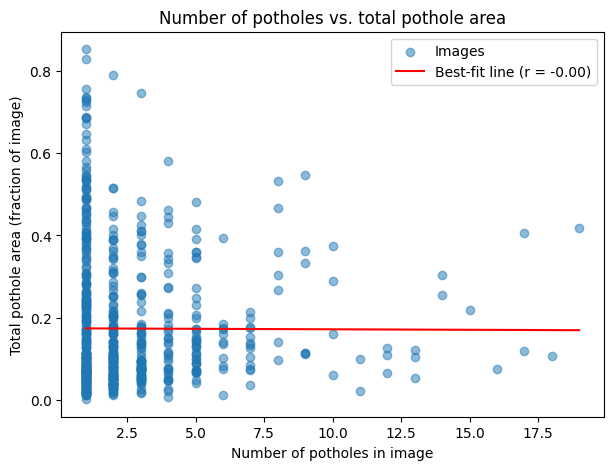

In [4]:
w, b = np.polyfit(x, y, 1)   # least-squares line y = w*x + b

plt.figure(figsize=(7, 5))
plt.scatter(x, y, alpha=0.5, label="Images")
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, w * xs + b, color="red", label=f"Best-fit line (r = {r_numpy:.2f})")
plt.xlabel("Number of potholes in image")
plt.ylabel("Total pothole area (fraction of image)")
plt.title("Number of potholes vs. total pothole area")
plt.legend()
plt.show()

## Interpretation

**What do the statistics tell me about the data?**
Most images contain about 2.6165 potholes (median 2.0), with a standard deviation of 2.5710, so the image contents vary a lot in terms of pothole counts. The pothole area fractions are small on average (mean of 0.1737 or 17.37% of the image) and heavily right-skewed because the mean is well above the median (0.1082). The image widths vary considerably (from 300 to 720 pixels), which is a key preprocessing detail because deep learning models require uniform input dimensions.

**What does the correlation tell me?**
Our Pearson correlation $r = -0.0039$ and sample covariance is $-0.0016$. The sign is slightly negative, indicating that images with more potholes have a negligibly smaller total area share covered by potholes. However, because the absolute value of $|r|$ is extremely close to 0, the relationship is very weak (virtually uncorrelated). The scatter plot confirms this, showing a highly scattered pattern where a single large pothole often dominates the image area, while images with many potholes often consist of tiny, low-area bounding boxes.

**Does correlation mean causation?**
No. Correlation only shows that two variables move together. Here the link is partly by construction: total area is built from the same boxes that are counted. In general, a hidden factor such as camera distance or road condition can drive both variables, so correlation alone cannot show that one variable causes the other. Establishing causation needs controlled experiments or domain evidence.

In [5]:
# Fit the simple model: output = w * input + b
w, b = np.polyfit(df["n_potholes"], df["total_box_area_frac"], 1)
print(f"total_area_frac = {w:.4f} * n_potholes + {b:.4f}")

# Example prediction
n_new = 3
print(f"Predicted pothole area share for {n_new} potholes: {w * n_new + b:.4f}")

total_area_frac = -0.0002 * n_potholes + 0.1743
Predicted pothole area share for 3 potholes: 0.1736


## Input → Function/Model → Output

$$\text{Input } x \;\longrightarrow\; f(x) = w\,x + b \;\longrightarrow\; \text{Output } \hat{y}$$

- **Input (x):** number of potholes detected in an image
- **Function/model f:** a straight line with slope $w$ and intercept $b$, learned from the data by least squares
- **Output ($\hat{y}$):** predicted fraction of the image covered by potholes

Using the fitted values: $\hat{y} = -0.0002\,x + 0.1743$.

This is the same idea as my full project, where the input is a road image, the model is a CNN, and the output is the pothole severity class:
$$\text{image} \rightarrow f_\theta(\text{image}) \rightarrow \text{severity}$$
